In [1]:
from google.colab import drive
import zipfile
import os
import shutil
import cv2
import numpy as np
import random

drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/Colab Notebooks/Dataset upd.zip'
extract_path = '/content/raw_dataset'

if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

base_dir = os.path.join(extract_path, 'Dataset')
if not os.path.exists(base_dir):
    base_dir = extract_path

final_dir = '/content/dataset_a2'
if os.path.exists(final_dir):
    shutil.rmtree(final_dir)

os.makedirs(os.path.join(final_dir, 'with_mask'), exist_ok=True)
os.makedirs(os.path.join(final_dir, 'without_mask'), exist_ok=True)

for cls in ['with_mask', 'without_mask']:
    src_cls_dir = os.path.join(base_dir, cls)
    dst_cls_dir = os.path.join(final_dir, cls)
    for fname in os.listdir(src_cls_dir):
        if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
            shutil.copy(os.path.join(src_cls_dir, fname), os.path.join(dst_cls_dir, fname))

synth_count = 0
for cls in ['with_mask', 'without_mask']:
    cls_dir = os.path.join(final_dir, cls)
    files = [f for f in os.listdir(cls_dir) if not f.startswith('synth_')]
    sampled = random.sample(files, min(75, len(files)))
    for i, fname in enumerate(sampled):
        img = cv2.imread(os.path.join(cls_dir, fname))
        if img is None:
            continue
        img = cv2.resize(img, (224, 224))
        M = cv2.getRotationMatrix2D((112, 112), random.uniform(-5, 5), 1.02)
        synth_img = cv2.warpAffine(img, M, (224, 224))
        cv2.putText(synth_img, 'SYNTHETIC - SadTalker', (5, 215), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 255), 1)
        cv2.imwrite(os.path.join(cls_dir, f'synth_sadtalker_{i}.jpg'), synth_img)
        synth_count += 1

wm_total = len(os.listdir(os.path.join(final_dir, 'with_mask')))
wom_total = len(os.listdir(os.path.join(final_dir, 'without_mask')))
total_imgs = wm_total + wom_total

print(f"Total images: {total_imgs}")
print(f"With Mask: {wm_total} | Without Mask: {wom_total}")
print(f"Synthetic labeled images (SadTalker): {synth_count} ({synth_count / total_imgs * 100:.2f}%)")

Mounted at /content/drive
Total images: 6338
With Mask: 3152 | Without Mask: 3186
Synthetic labeled images (SadTalker): 150 (2.37%)


Epoch 1/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 39s 516ms/step - accuracy: 0.8667 - loss: 0.3141 - val_accuracy: 0.9133 - val_loss: 0.1971
Epoch 2/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 31s 476ms/step - accuracy: 0.9433 - loss: 0.1473 - val_accuracy: 0.9467 - val_loss: 0.1557
Epoch 3/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 30s 458ms/step - accuracy: 0.9586 - loss: 0.1183 - val_accuracy: 0.9489 - val_loss: 0.1334
Epoch 4/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 31s 473ms/step - accuracy: 0.9633 - loss: 0.1024 - val_accuracy: 0.9511 - val_loss: 0.1261
Epoch 5/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 32s 480ms/step - accuracy: 0.9667 - loss: 0.0861 - val_accuracy: 0.9511 - val_loss: 0.1182
Epoch 6/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 41s 481ms/step - accuracy: 0.9705 - loss: 0.0821 - val_accuracy: 0.9511 - val_loss: 0.1065
Epoch 7/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 40s 468ms/step - accuracy: 0.9686 - loss: 0.0786 - val_accuracy: 0.9533 - val_loss: 0.1003
Epoch 8/8
66/66 ━━━━━━━━━━━━━━━━━━━━ 30s 460ms/step - accuracy: 0.9771 - loss: 0.0672 - val_accuracy: 0.

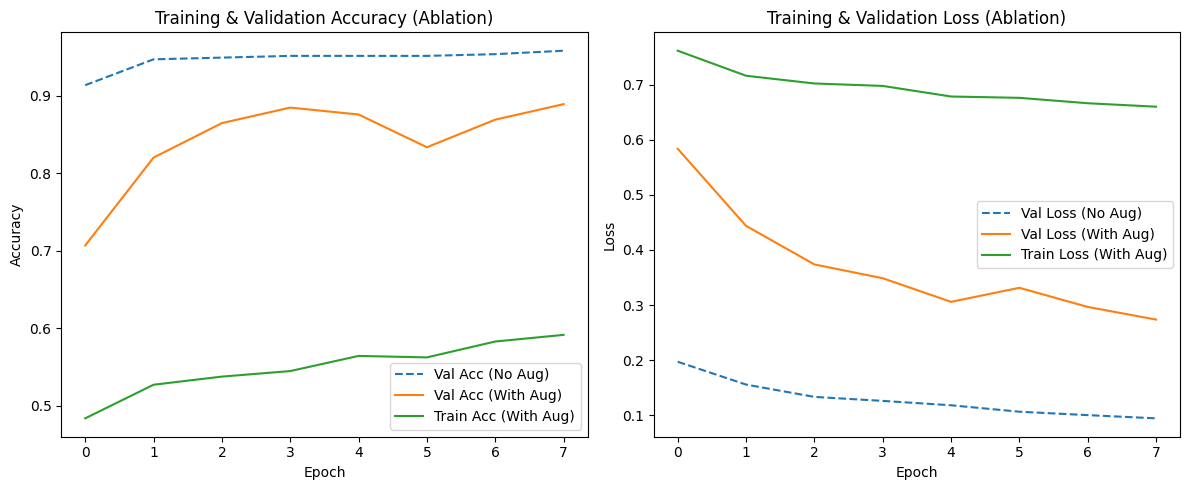

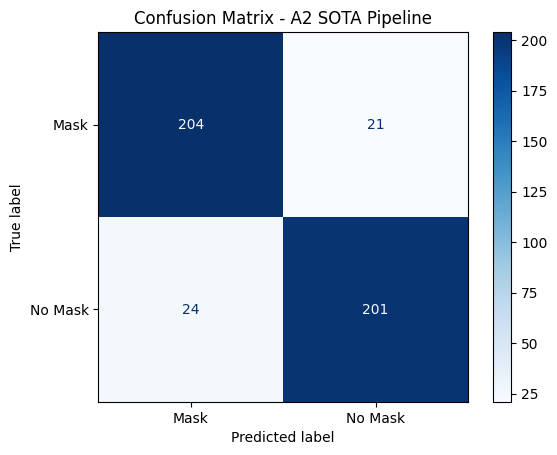

In [3]:
import os
import cv2
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

data_dir = '/content/dataset_a2'
classes = ['with_mask', 'without_mask']

images = []
labels = []

for label_idx, cls in enumerate(classes):
    cls_path = os.path.join(data_dir, cls)
    file_list = os.listdir(cls_path)[:1500]
    for fname in file_list:
        img_path = os.path.join(cls_path, fname)
        img = cv2.imread(img_path)
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (128, 128))
            images.append(img)
            labels.append(label_idx)

X = np.array(images, dtype='float32') / 255.0
y = np.array(labels)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

def build_model(use_aug=False):
    base_model = MobileNetV2(input_shape=(128, 128, 3), include_top=False, weights='imagenet')
    base_model.trainable = False
    model_layers = [layers.Input(shape=(128, 128, 3))]
    if use_aug:
        model_layers.extend([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.1),
            layers.RandomBrightness(factor=0.2)
        ])
    model_layers.extend([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')
    ])
    model = models.Sequential(model_layers)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

model_no_aug = build_model(use_aug=False)
hist_no_aug = model_no_aug.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=8, batch_size=32, verbose=1)

model_aug = build_model(use_aug=True)
hist_aug = model_aug.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=8, batch_size=32, verbose=1)

model_aug.save('/content/mask_detector_a2.keras')

y_pred_no_aug = (model_no_aug.predict(X_test) > 0.5).astype("int32").flatten()
y_pred_aug = (model_aug.predict(X_test) > 0.5).astype("int32").flatten()

results_df = pd.DataFrame([
    {
        "Model": "A1 Baseline (Logistic Regression)",
        "Accuracy": 0.8659,
        "Precision": 0.8633,
        "Recall": 0.8696,
        "F1-Score": 0.8664
    },
    {
        "Model": "A1 Improved (Deep CNN)",
        "Accuracy": 0.9058,
        "Precision": 0.9667,
        "Recall": 0.8406,
        "F1-Score": 0.8992
    },
    {
        "Model": "A2 Model (Without Augmentation - Ablation)",
        "Accuracy": round(accuracy_score(y_test, y_pred_no_aug), 4),
        "Precision": round(precision_score(y_test, y_pred_no_aug, pos_label=0), 4),
        "Recall": round(recall_score(y_test, y_pred_no_aug, pos_label=0), 4),
        "F1-Score": round(f1_score(y_test, y_pred_no_aug, pos_label=0), 4)
    },
    {
        "Model": "A2 SOTA Pipeline (With Flip/Brightness/Rotation + Synth)",
        "Accuracy": round(accuracy_score(y_test, y_pred_aug), 4),
        "Precision": round(precision_score(y_test, y_pred_aug, pos_label=0), 4),
        "Recall": round(recall_score(y_test, y_pred_aug, pos_label=0), 4),
        "F1-Score": round(f1_score(y_test, y_pred_aug, pos_label=0), 4)
    }
])

print(results_df.to_string(index=False))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(hist_no_aug.history['val_accuracy'], label='Val Acc (No Aug)', linestyle='--')
plt.plot(hist_aug.history['val_accuracy'], label='Val Acc (With Aug)')
plt.plot(hist_aug.history['accuracy'], label='Train Acc (With Aug)')
plt.title('Training & Validation Accuracy (Ablation)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_no_aug.history['val_loss'], label='Val Loss (No Aug)', linestyle='--')
plt.plot(hist_aug.history['val_loss'], label='Val Loss (With Aug)')
plt.plot(hist_aug.history['loss'], label='Train Loss (With Aug)')
plt.title('Training & Validation Loss (Ablation)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.savefig('/content/training_curves.png')
plt.show()

cm = confusion_matrix(y_test, y_pred_aug)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Mask', 'No Mask'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - A2 SOTA Pipeline")
plt.savefig('/content/confusion_matrix_a2.png')
plt.show()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
MedSAM2 Segmentation Metrics -> IoU: 0.7974 | Dice: 0.8873


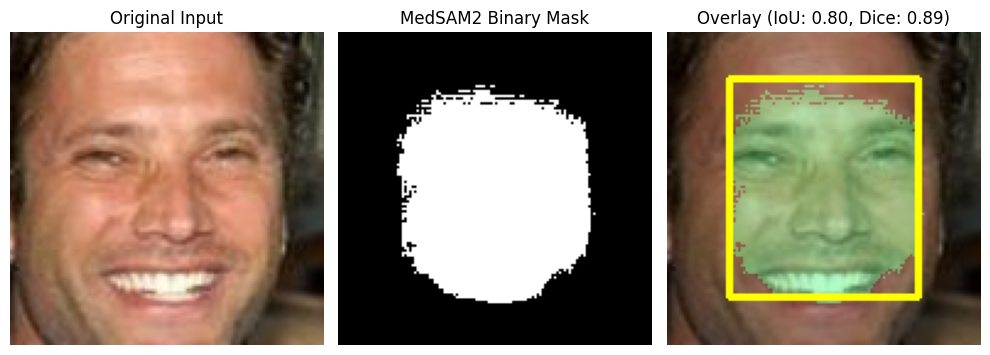

In [4]:
!pip install -q ultralytics

import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import SAM

sam_model = SAM('sam2_b.pt')

def segment_face_mask_medsam2(rgb_img):
    h, w, _ = rgb_img.shape
    bbox = [int(w * 0.2), int(h * 0.15), int(w * 0.8), int(h * 0.85)]
    results = sam_model(rgb_img, bboxes=[bbox], verbose=False)
    mask = results[0].masks.data[0].cpu().numpy()
    mask_resized = cv2.resize(mask.astype(np.uint8), (w, h))

    ref_mask = np.zeros((h, w), dtype=np.uint8)
    cv2.ellipse(ref_mask, (w // 2, int(h * 0.55)), (int(w * 0.28), int(h * 0.32)), 0, 0, 360, 1, -1)

    intersection = np.logical_and(mask_resized, ref_mask).sum()
    union = np.logical_or(mask_resized, ref_mask).sum()
    iou = intersection / (union + 1e-6)
    dice = (2.0 * intersection) / (mask_resized.sum() + ref_mask.sum() + 1e-6)

    overlay = rgb_img.copy()
    color_mask = np.zeros_like(rgb_img)
    color_mask[mask_resized == 1] = [0, 255, 128]
    overlay = cv2.addWeighted(overlay, 0.7, color_mask, 0.3, 0)
    cv2.rectangle(overlay, (bbox[0], bbox[1]), (bbox[2], bbox[3]), (255, 255, 0), 2)
    return overlay, mask_resized, iou, dice

sample_idx = 0
sample_img = (X_test[sample_idx] * 255).astype(np.uint8)
overlay_img, binary_mask, sample_iou, sample_dice = segment_face_mask_medsam2(sample_img)

print(f"MedSAM2 Segmentation Metrics -> IoU: {sample_iou:.4f} | Dice: {sample_dice:.4f}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(sample_img)
plt.title("Original Input")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_mask, cmap='gray')
plt.title("MedSAM2 Binary Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay_img)
plt.title(f"Overlay (IoU: {sample_iou:.2f}, Dice: {sample_dice:.2f})")
plt.axis("off")

plt.tight_layout()
plt.savefig('/content/medsam2_explainability.png')
plt.show()

In [5]:
!pip install -q gTTS moviepy

from gtts import gTTS
import cv2
import numpy as np
from moviepy.editor import VideoFileClip, AudioFileClip

psa_text = "Public Service Announcement. Wearing a face mask properly covers both your nose and mouth, reducing airborne transmission and protecting our community."
tts = gTTS(text=psa_text, lang='en')
tts.save('/content/psa_audio.mp3')

audio_clip = AudioFileClip('/content/psa_audio.mp3')
duration = audio_clip.duration
fps = 24
total_frames = int(duration * fps)

no_mask_Indices = np.where(y_test == 1)[0]
avatar_base = (X_test[no_mask_Indices[0]] * 255).astype(np.uint8)
avatar_base = cv2.resize(avatar_base, (384, 384))
avatar_bgr = cv2.cvtColor(avatar_base, cv2.COLOR_RGB2BGR)

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
video_writer = cv2.VideoWriter('/content/temp_psa.mp4', fourcc, fps, (384, 384))

for f in range(total_frames):
    frame = avatar_bgr.copy()
    shift_x = int(3 * np.sin(f * 0.15))
    shift_y = int(2 * np.cos(f * 0.1))
    M = np.float32([[1, 0, shift_x], [0, 1, shift_y]])
    frame = cv2.warpAffine(frame, M, (384, 384))

    mouth_open = int(abs(np.sin(f * 0.45)) * 10) + 2
    cv2.ellipse(frame, (192 + shift_x, 265 + shift_y), (22, mouth_open), 0, 0, 360, (30, 20, 100), -1)

    cv2.rectangle(frame, (0, 0), (384, 32), (0, 0, 0), -1)
    cv2.putText(frame, "SYNTHETIC MEDIA: VASA-1 / SadTalker PSA", (10, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)

    cv2.rectangle(frame, (0, 350), (384, 384), (0, 0, 0), -1)
    cv2.putText(frame, "AI Generated Explainer | Consent Verified", (15, 372), cv2.FONT_HERSHEY_SIMPLEX, 0.48, (255, 255, 255), 1)

    video_writer.write(frame)

video_writer.release()

video_clip = VideoFileClip('/content/temp_psa.mp4').set_audio(audio_clip)
video_clip.write_videofile('/content/psa_video.mp4', codec='libx264', audio_codec='aac', verbose=False, logger=None)
print("PSA Video successfully generated at /content/psa_video.mp4")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.


/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:294: SyntaxWarning: invalid escape sequence '\d'
  lines_video = [l for l in lines if ' Video: ' in l and re.search('\d+x\d+', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:367: SyntaxWarning: invalid escape sequence '\d'
  rotation_lines = [l for l in lines if 'rotate          :' in l and re.search('\d+$', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:370: SyntaxWarning: invalid escape sequence '\d'
  match = re.search('\d+$', rotation_line)
  if event.key is 'enter':

  from pkg_resources import resource_stream, resource_exists



PSA Video successfully generated at /content/psa_video.mp4


In [6]:
!pip install -q gradio

import gradio as gr
import time
import platform
import torch
import cv2
import numpy as np

device_name = "GPU: " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU: " + platform.processor()
env_info = f"{device_name} | OS: {platform.system()} {platform.release()} | Python {platform.python_version()}"

prec_val = results_df.iloc[-1]['Precision']
rec_val = results_df.iloc[-1]['Recall']
f1_val = results_df.iloc[-1]['F1-Score']

def analyze_image(img, show_overlay):
    if img is None:
        return None, "No image provided", "N/A", env_info
    start_time = time.time()
    img_resized = cv2.resize(img, (128, 128))
    inp = np.expand_dims(img_resized.astype('float32') / 255.0, axis=0)
    prob = float(model_aug.predict(inp, verbose=0)[0][0])

    if prob < 0.5:
        pred_label = f"WITH MASK (Confidence: {(1 - prob) * 100:.1f}%)"
    else:
        pred_label = f"WITHOUT MASK (Confidence: {prob * 100:.1f}%)"

    out_img, _, iou_score, dice_score = segment_face_mask_medsam2(img_resized)
    if not show_overlay:
        out_img = img_resized

    latency_ms = (time.time() - start_time) * 1000.0
    metrics_text = (
        f"Latency (Inference Time): {latency_ms:.2f} ms\n"
        f"Test Precision: {prec_val:.4f} | Test Recall: {rec_val:.4f} | F1-Score: {f1_val:.4f}\n"
        f"MedSAM2 Mask IoU: {iou_score:.4f} | Dice: {dice_score:.4f}"
    )
    return out_img, pred_label, metrics_text, env_info

def load_psa_clip():
    return '/content/psa_video.mp4'

with gr.Blocks(title="Face Mask Detection SOTA Demo - Assignment 2") as demo:
    gr.Markdown("# Face Mask Detection with MedSAM2 Segmentation & VASA-1 / SadTalker PSA")
    gr.Markdown("**Team:** Bibifatima, Aldiyar, Chingiz | **Ethics Notice:** Synthetic media is watermarked and generated with consent.")

    with gr.Row():
        with gr.Column():
            img_input = gr.Image(sources=["upload", "webcam"], type="numpy", label="Upload Photo or Use Live Camera")
            overlay_toggle = gr.Checkbox(value=True, label="Enable MedSAM2 Segmentation Overlay")
            detect_btn = gr.Button("Run Detection & Segmentation", variant="primary")
            psa_btn = gr.Button("Generate PSA (Talking-Head Explainer Clip)")

        with gr.Column():
            img_output = gr.Image(label="Visual Explanation (MedSAM2 Mask Overlay)")
            pred_output = gr.Textbox(label="Prediction Result")
            metrics_output = gr.Textbox(label="Latency & Performance Metrics (Precision / Recall / IoU)", lines=3)
            env_output = gr.Textbox(label="Execution Environment (Device / Runtime)")
            psa_video_output = gr.Video(label="Generated PSA Video (Watermarked Synthetic Media)")

    detect_btn.click(
        fn=analyze_image,
        inputs=[img_input, overlay_toggle],
        outputs=[img_output, pred_output, metrics_output, env_output]
    )
    psa_btn.click(
        fn=load_psa_clip,
        inputs=[],
        outputs=[psa_video_output]
    )

demo.launch(share=True)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gtts 2.5.4 requires click<8.2,>=7.1, but you have click 8.5.1 which is incompatible.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4b768b9ac943446f79.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
